<a href="https://colab.research.google.com/github/Ashwini9713/fundamentals-of-ML/blob/main/EXP_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

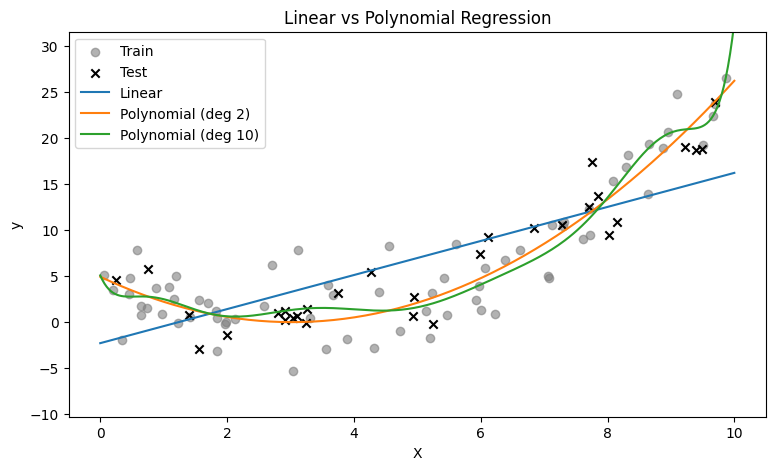

,Model,Train R2,Test R2,Test RMSE
0,Linear,0.564,0.724,3.791
1,Polynomial (deg 2),0.854,0.880,2.502
2,Polynomial (deg 10),0.869,0.871,2.595


<Figure size 640x480 with 0 Axes>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# 1. Generate non-linear data
np.random.seed(42)
X = np.sort(np.random.uniform(0, 10, 100)).reshape(-1, 1)
y = 0.5 * X.ravel()**2 - 3 * X.ravel() + 5 + np.random.normal(0, 3, 100)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

# 2. Models
models = {
    "Linear": make_pipeline(LinearRegression()),
    "Polynomial (deg 2)": make_pipeline(PolynomialFeatures(2), LinearRegression()),
    "Polynomial (deg 10)": make_pipeline(PolynomialFeatures(10), LinearRegression()),
}

# 3. Train, evaluate, plot
X_plot = np.linspace(0, 10, 300).reshape(-1, 1)
plt.figure(figsize=(9, 5))
plt.scatter(X_train, y_train, c="gray", alpha=0.6, label="Train")
plt.scatter(X_test, y_test, c="black", marker="x", label="Test")

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    results.append({
        "Model": name,
        "Train R2": r2_score(y_train, model.predict(X_train)),
        "Test R2": r2_score(y_test, model.predict(X_test)),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, model.predict(X_test))),
    })
    plt.plot(X_plot, model.predict(X_plot), label=name)

plt.ylim(y.min() - 5, y.max() + 5)
plt.title("Linear vs Polynomial Regression")
plt.xlabel("X"); plt.ylabel("y"); plt.legend()
plt.show()

# 4. Comparison table
display(pd.DataFrame(results).round(3))
plt.savefig("regression_comparison.png", dpi=120)